# Week 10 — Contrast Agents (CT & MRI)

Many structures (blood vessels, tumors, inflamed tissue) have almost the **same** native attenuation
or relaxation as their surroundings, so they are invisible. **Contrast agents** are injected to
*temporarily* change a tissue property and make those structures stand out.

| | CT | MRI |
|---|---|---|
| Agent | **iodine** (Z=53), barium | **gadolinium** (Gd$^{3+}$) chelates |
| Mechanism | raises linear attenuation $\mu$ → **higher HU** | paramagnetic → **shortens $T_1$** |
| Effect | enhancing structures look **bright** | bright on **$T_1$-weighted** images |

This notebook simulates: iodine raising **Hounsfield units**, the iodine **K-edge** and optimal kVp,
the **time–attenuation (bolus)** curve, and gadolinium **$T_1$ shortening** in MRI.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

## 1. CT: iodine raises attenuation (Hounsfield units)

Iodine has a high atomic number, so it strongly attenuates X-rays (mostly by the **photoelectric**
effect). Blood opacified with iodine gains attenuation roughly **linearly** with concentration — about
**+25–30 HU per mg iodine/mL** at typical energies. Recall $\text{HU}=1000\,(\mu-\mu_\text{water})/\mu_\text{water}$,
so water = 0 HU; unenhanced blood ≈ 40 HU; enhanced arteries reach **300–400+ HU**.

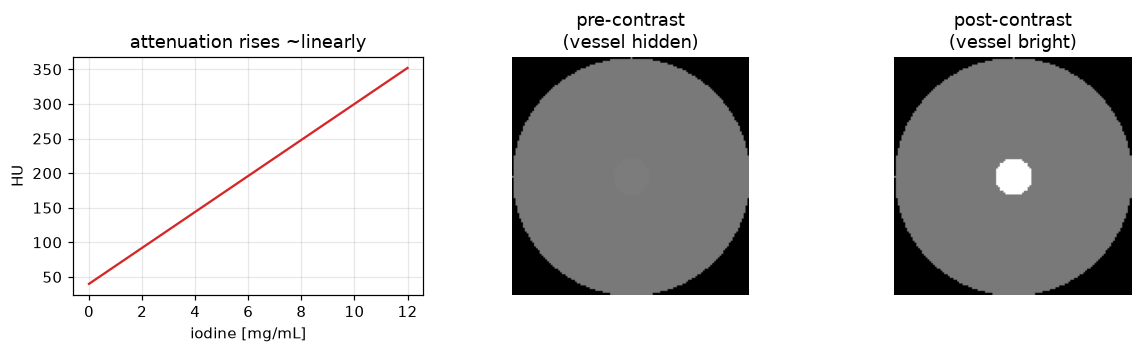

enhanced vessel: 300 HU vs soft tissue 40 HU


In [3]:
conc = np.linspace(0, 12, 100)                 # iodine concentration [mg/mL]
k_HU = 26.0                                     # enhancement slope [HU per mg/mL]
blood_base = 40.0                               # unenhanced blood [HU]
HU = blood_base + k_HU * conc

# A simple vessel phantom; inject contrast -> the vessel's HU jumps
N = 128
yy, xx = np.ogrid[:N, :N]
tissue = np.full((N, N), 40.0)                   # soft tissue ~40 HU
tissue[np.hypot(xx - N//2, yy - N//2) > N//2] = -1000       # air outside
vessel = np.hypot(xx - N//2, yy - N//2) < 10
pre = tissue.copy();  pre[vessel] = 45           # vessel ~ blood, nearly invisible
post = tissue.copy(); post[vessel] = blood_base + k_HU * 10  # after 10 mg/mL iodine

def ct_window(img, center=50, width=400):
    lo, hi = center - width/2, center + width/2
    return np.clip((img - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
ax[0].plot(conc, HU, color="tab:red"); ax[0].set_xlabel("iodine [mg/mL]"); ax[0].set_ylabel("HU")
ax[0].set_title("attenuation rises ~linearly"); ax[0].grid(alpha=0.3)
ax[1].imshow(ct_window(pre), cmap="gray", vmin=0, vmax=1); ax[1].set_title("pre-contrast\n(vessel hidden)"); ax[1].axis("off")
ax[2].imshow(ct_window(post), cmap="gray", vmin=0, vmax=1); ax[2].set_title("post-contrast\n(vessel bright)"); ax[2].axis("off")
plt.tight_layout(); plt.show()
print(f"enhanced vessel: {post[vessel].mean():.0f} HU vs soft tissue 40 HU")

## 2. The iodine K-edge and why ~80 kVp maximizes contrast

Iodine's **K-edge** at **33.2 keV** causes a sharp jump in its mass attenuation: photons just above
33 keV are absorbed far more strongly. Because a diagnostic beam's mean energy sits not far above this,
lowering the tube voltage (e.g. **80 kVp** instead of 120 kVp) pushes more of the spectrum toward the
K-edge and **boosts iodine contrast** (the basis of low-kVp and dual-energy angiography).

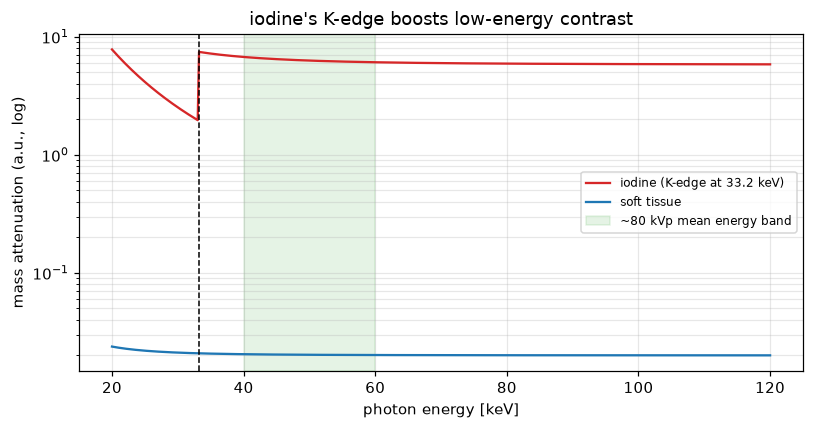

In [4]:
E = np.linspace(20, 120, 500)                    # keV
# Soft tissue: smooth photoelectric + Compton falloff
mu_tissue = 0.02 + 30.0 / E**3
# Iodine: same falloff but with a K-edge jump at 33.2 keV
mu_iodine = 0.3 + 6.0e4 / E**3
mu_iodine[E > 33.2] += 5.5                        # K-edge discontinuity

plt.figure(figsize=(7.5, 4))
plt.semilogy(E, mu_iodine, color="tab:red", label="iodine (K-edge at 33.2 keV)")
plt.semilogy(E, mu_tissue, color="tab:blue", label="soft tissue")
plt.axvline(33.2, color="k", ls="--", lw=1)
plt.axvspan(40, 60, color="tab:green", alpha=0.12, label="~80 kVp mean energy band")
plt.xlabel("photon energy [keV]"); plt.ylabel("mass attenuation (a.u., log)")
plt.title("iodine's K-edge boosts low-energy contrast")
plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

## 3. The time–attenuation (bolus) curve

Contrast is injected as a **bolus** and the scan must be timed to the phase of interest. As the bolus
circulates, a vessel's enhancement rises to an **arterial peak**, then washes out while the **venous**
and tissue phases follow a few seconds later. A **gamma-variate** function models each passage.

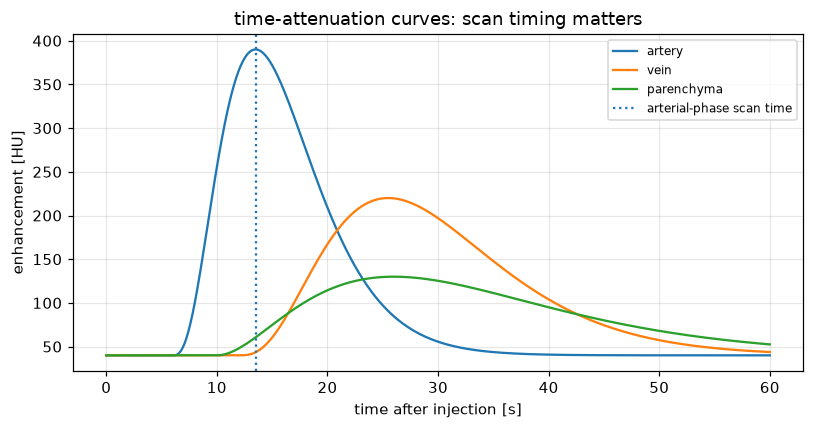

In [5]:
t = np.linspace(0, 60, 600)                       # seconds after injection

def gamma_variate(t, t0, alpha, beta, peak_HU):
    x = np.clip(t - t0, 0, None)
    y = x**alpha * np.exp(-x / beta)
    return 40 + peak_HU * y / y.max()             # baseline 40 HU + scaled enhancement

arterial = gamma_variate(t, t0=6,  alpha=3.0, beta=2.5, peak_HU=350)
venous   = gamma_variate(t, t0=12, alpha=3.0, beta=4.5, peak_HU=180)
parench  = gamma_variate(t, t0=10, alpha=2.0, beta=8.0, peak_HU=90)

plt.figure(figsize=(7.5, 4))
plt.plot(t, arterial, label="artery")
plt.plot(t, venous, label="vein")
plt.plot(t, parench, label="parenchyma")
plt.axvline(t[np.argmax(arterial)], color="tab:blue", ls=":", label="arterial-phase scan time")
plt.xlabel("time after injection [s]"); plt.ylabel("enhancement [HU]")
plt.title("time-attenuation curves: scan timing matters")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. MRI: gadolinium shortens $T_1$

Gadolinium is **paramagnetic**; it provides a fast relaxation pathway that **shortens $T_1$** in
proportion to its concentration (relaxivity $r_1$):
$$\frac{1}{T_1} = \frac{1}{T_{1,0}} + r_1\,C.$$
On a $T_1$-weighted spoiled gradient echo, signal $S = M_0\,(1-e^{-TR/T_1})$ **rises** as $T_1$ falls,
so enhancing tissue looks **bright**. (At very high doses $T_2^\*$ effects eventually darken it again.)

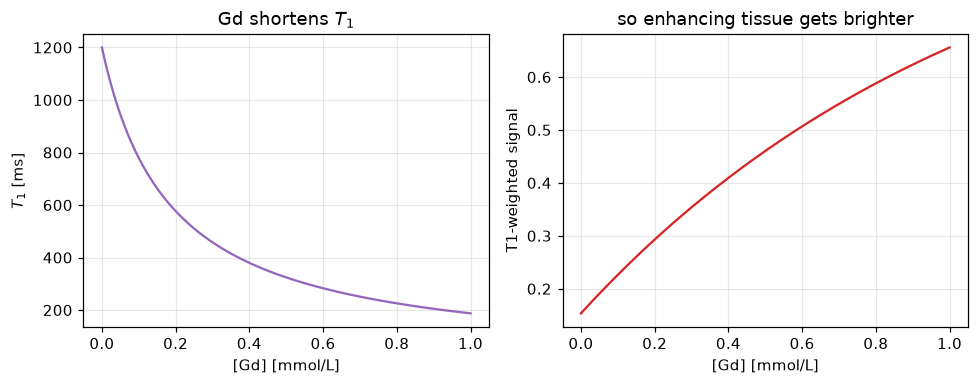

T1: 1200 ms (native) -> 188 ms (enhanced);  signal x4.27


In [6]:
C = np.linspace(0, 1.0, 200)                      # [Gd] [mmol/L]
T1_0 = 1200.0                                     # native tissue T1 [ms]
r1 = 4.5                                          # relaxivity [L/(mmol*s)] -> per ms below
T1 = 1.0 / (1.0 / T1_0 + r1 * C / 1000.0)         # shortened T1 [ms]
TR = 200.0                                         # repetition time [ms]
S = 1 - np.exp(-TR / T1)                           # T1-weighted signal (M0 = 1)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].plot(C, T1, color="tab:purple"); ax[0].set_xlabel("[Gd] [mmol/L]"); ax[0].set_ylabel("$T_1$ [ms]")
ax[0].set_title("Gd shortens $T_1$"); ax[0].grid(alpha=0.3)
ax[1].plot(C, S, color="tab:red"); ax[1].set_xlabel("[Gd] [mmol/L]"); ax[1].set_ylabel("T1-weighted signal")
ax[1].set_title("so enhancing tissue gets brighter"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"T1: {T1[0]:.0f} ms (native) -> {T1[-1]:.0f} ms (enhanced);  signal x{S[-1]/S[0]:.2f}")

## Takeaways

- Contrast agents **temporarily change a tissue property** to reveal otherwise-invisible structures.
- **CT / iodine**: raises $\mu$ → **higher HU** (~+26 HU per mg/mL); arteries reach 300–400+ HU.
- The iodine **K-edge (33.2 keV)** means **lower kVp** (≈80) boosts contrast — the idea behind
  low-kVp and **dual-energy** CT angiography.
- **Bolus timing** is critical: arterial, venous, and parenchymal phases peak seconds apart
  (gamma-variate dynamics).
- **MRI / gadolinium**: shortens $T_1$ ($1/T_1 = 1/T_{1,0} + r_1 C$) → **bright on $T_1$-weighted**
  images; the CT analogue of iodine enhancement.